
Suppose if the library is not available in google colab. we have to install it using the commands


In [ ]:
!pip install -U scikit-learn #Installing scikit-learn library

In [ ]:
import pandas as pd # Load the dataset
import numpy as np


# Importing the Dataset

In [ ]:
dataset = pd.read_csv("/content/Salary_Data.csv")

# Exploring the Dataset

In [ ]:
dataset.head() # Displays first 5 rows

,YearsExperience,Age,Salary
0,1.1,21.0,39343
1,1.3,21.5,46205
2,1.5,21.7,37731
3,2.0,22.0,43525
4,2.2,22.2,39891


In [ ]:
dataset.dtypes

,0
YearsExperience,float64
Age,float64
Salary,int64


In [ ]:
dataset.shape # displays the dimension of the dataset

(30, 3)

# Checking Null Values

In [ ]:
dataset.isnull().sum()

,0
YearsExperience,0
Age,0
Salary,0


In [ ]:
dataset.duplicated

<bound method DataFrame.duplicated of     YearsExperience   Age  Salary
0               1.1  21.0   39343
1               1.3  21.5   46205
2               1.5  21.7   37731
3               2.0  22.0   43525
4               2.2  22.2   39891
5               2.9  23.0   56642
6               3.0  23.0   60150
7               3.2  23.3   54445
8               3.2  23.3   64445
9               3.7  23.6   57189
10              3.9  23.9   63218
11              4.0  24.0   55794
12              4.0  24.0   56957
13              4.1  24.0   57081
14              4.5  25.0   61111
15              4.9  25.0   67938
16              5.1  26.0   66029
17              5.3  27.0   83088
18              5.9  28.0   81363
19              6.0  29.0   93940
20              6.8  30.0   91738
21              7.1  30.0   98273
22              7.9  31.0  101302
23              8.2  32.0  113812
24              8.7  33.0  109431
25              9.0  34.0  105582
26              9.5  35.0  116969
27              9.6  36.0  112635
28             10.3  37.0  122391
29             10.5  38.0  121872>

# Seggregating the dataset into training and testing

In [ ]:
X = dataset.iloc[:, 0:2]
y = dataset.iloc[:,2]

In [ ]:
X.head()

,YearsExperience,Age
0,1.1,21.0
1,1.3,21.5
2,1.5,21.7
3,2.0,22.0
4,2.2,22.2


In [ ]:
y.head()

,Salary
0,39343
1,46205
2,37731
3,43525
4,39891


In [ ]:
from scipy.stats import zscore

# Calculate Z-Scores for each feature
z_scores = np.abs(zscore(X))

# Define a threshold for identifying outliers
threshold = 3

# Identify rows where any feature has a Z-Score greater than the threshold
outliers = np.where(z_scores > threshold)

# Get unique rows that are outliers
unique_outliers = np.unique(outliers[0])


In [ ]:
print(unique_outliers)

[]


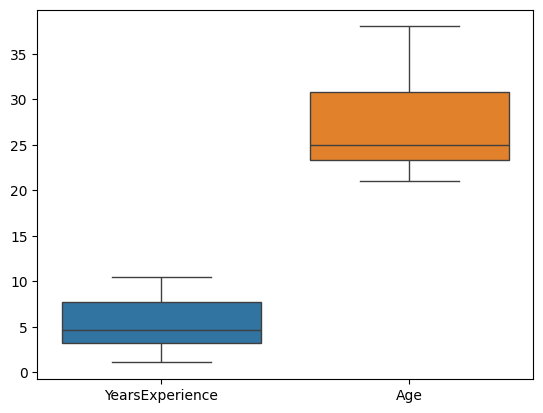

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=X)
plt.show()



# Splitting into Training and Testing sets

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2,random_state = 0)


In [ ]:
print(X_train.shape)
print(y_train.shape)

print(X_test.shape)

(24, 2)
(24,)
(6, 2)


# Standardizing the features

In [ ]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [ ]:
X_train

array([[ 1.75832984,  1.97734469],
       [-0.40973925, -0.58670426],
       [ 0.09356251,  0.05430798],
       [ 1.10016601,  0.90899096],
       [-0.83560996, -0.800375  ],
       [ 0.01613147, -0.15936276],
       [-0.7194634 , -0.73627378],
       [-0.21616165, -0.37303351],
       [ 1.21631257,  1.12266171],
       [ 0.6742953 ,  0.69532022],
       [-1.45505827, -1.12088112],
       [ 2.10676952,  2.40468619],
       [-0.79689444, -0.800375  ],
       [-1.1066186 , -0.9713116 ],
       [ 0.32585562,  0.26797873],
       [ 0.36457114,  0.48164947],
       [-0.52588581, -0.67217255],
       [-0.7194634 , -0.73627378],
       [ 1.52603672,  1.5500032 ],
       [-1.18404964, -1.01404575],
       [-1.53248931, -1.22771649],
       [ 0.79044186,  0.69532022],
       [-0.06129957, -0.37303351],
       [-0.40973925, -0.58670426]])

In [ ]:
y_train

,Salary
27,112635
11,55794
17,83088
22,101302
5,56642
16,66029
8,64445
14,61111
23,113812
20,91738


# Model Development

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

mse = []

for depth in range(1,11):
  model = DecisionTreeRegressor(max_depth=depth, random_state=0)
  model.fit(X_train, y_train)
  pred = model.predict(X_test)
  mse.append(mean_squared_error(pred,y_test))

In [ ]:
mse

[202201797.79166666,
 24539495.03125,
 16128775.736689823,
 23599498.75,
 59139641.537037045,
 59797386.416666664,
 43979023.916666664,
 41317350.916666664,
 41317350.916666664,
 41317350.916666664]

In [ ]:
best_mse = min(mse)
best_mse

16128775.736689823

In [ ]:
best_depth = mse.index(best_mse) + 1
best_depth

3

In [ ]:
model = DecisionTreeRegressor(max_depth=3)
model.fit(X_train,y_train)

DecisionTreeRegressor(max_depth=3)

In [ ]:
from sklearn.metrics import mean_absolute_error

mean_absolute_error(y_pred, y_test)

5144.277777777778

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
y_test = y_test.to_numpy()

In [ ]:
pred_array = y_pred.reshape(len(y_pred), 1)
test_array = y_test.reshape(len(y_test), 1)
print(np.concatenate((pred_array, test_array), axis=1))


[[ 43207.          37731.        ]
 [110676.33333333 122391.        ]
 [ 58341.625       57081.        ]
 [ 58341.625       63218.        ]
 [110676.33333333 116969.        ]
 [110676.33333333 109431.        ]]


In [ ]:
from sklearn.linear_model import Ridge


model = Ridge(alpha=1.0)

# Fit the model to the training data
model.fit(X_train, y_train)

# Evaluate the model on the test data
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
print(f"Mean Absolute Error: {mae}")
print(mean_squared_error(y_test, predictions))

Mean Absolute Error: 3403.8859450777513
15946743.14088208


# Prediction

In [ ]:
age = float(input("Enter your age:"))
experience = float(input("Enter your year of Experience:"))
new_standardize = sc.transform([[age,experience]])
new_prediction = model.predict(new_standardize)
print(new_prediction[0])


Enter your age:25
Enter your year of Experience:3.6
121872.0
